# D6 · Pérdida proyectada por fuga

**Integrante responsable: Joel Huillca Lima**

Notebook de sustentación de la dimensión D6 (Unidad 2, Grupo Horeb, MonitorAqua).

- **Modelo versionado:** `d6.1` (`batch/modelos/d6/d6.1-20261029/modelo.json`): tasa nocturna robusta (Theil-Sen),
  clasificador logístico de fuga, pérdida proyectada con factor de persistencia y banda conforme de Mondrian.
- **Sin modelo propio:** todo se importa de `batch/modelo_d6.py`, `batch/fuga.py`, `batch/modelo_d6_mllib.py` y
  `batch/evaluacion.py`.
- **Fuente de verdad:** `docs/modelo-d6.md` y `docs/evidencias/f6-d6/`.
- **Advertencia:** no hay ninguna fuga real etiquetada; toda la detección y los litros son **consistencia** con el
  generador, no rendimiento real.

In [1]:
# Dependencias que la imagen de Jupyter no trae (lectura de Parquet y gráficos). Versiones fijas.
%pip install -q --root-user-action=ignore --disable-pip-version-check pyarrow==19.0.1 matplotlib==3.10.7

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/u2/soporte_u2.py
import soporte_u2 as su                        # agrega batch/, ingesta/ y streaming/ al path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import evaluacion as ev
import modelo_d6 as m
import modelo_d6_mllib as mll
from detector_servicio import Configuracion, Detector
RAIZ = su.RAIZ
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)
MODELO = RAIZ / "batch/modelos/d6/d6.1-20261029"
PUB = json.loads((RAIZ / "docs/evidencias/f6-d6/resultados_d6.json").read_text(encoding="utf-8"))
print("Repositorio:", RAIZ)

Repositorio: /work/MonitorAqua


## 1. Pregunta y datos

**Pregunta:** ¿este tanque pierde agua por fuga? ¿A cuántos L/h, y cuánto perderá en 24 h si nadie actúa?
**Decisión que apoya:** revisar flotador, uniones y llave; dimensionar el costo de no arreglar.

**Datos:** una fila por noche (franja 00:00-03:30 Lima). La flota se reconstruye con el mismo generador y semillas
(12 de entrenamiento y 12 **distintas** de evaluación, f2b.2 y f2b.3; desde la caché `batch/datos/d6_cache/`) y se
comprueba contra la tabla oro `d6_noches` (partición **p6.2**). ThingSpeak aporta el descenso nocturno real; el ESP32,
una sola noche de diseño.

In [3]:
t0 = time.time()
dT_jul = m.juliaca()
det = Detector(Configuracion(str(m.REGLAS), str(RAIZ / "ingesta/tanques.yml")))
assert det.cfg.reglas["version"] == "f4.4"
corridas = []
for modelo in m.CFG["flota"]:
    for uso in ("entrenamiento", "evaluacion"):
        for s in m.CFG[f"semillas_{uso}"]:
            n, run = m.corrida(modelo, s, det, dT_jul)
            corridas.append(n.assign(uso=uso))
flota = pd.concat(corridas, ignore_index=True)
control = m.comprobar_oro(flota[flota["uso"] == "entrenamiento"])
assert not set(m.CFG["semillas_entrenamiento"]) & set(m.CFG["semillas_evaluacion"])
print(f"Flota: {len(flota)} noches de {len(corridas)} corridas en {time.time() - t0:.0f} s")
print("Control contra la tabla oro d6_noches:", control)
oro = ev.leer_oro("d6_noches")
print("Partición de la tabla oro:", ", ".join(oro["particion_version"].unique()))
display(pd.crosstab([flota["fuente"], flota["uso"]], flota["particion"], margins=True, margins_name="total"))

Flota: 5760 noches de 48 corridas en 2 s
Control contra la tabla oro d6_noches: {'runId': ['r7-79a6b935'], 'noches_oro': 120, 'noches_emparejadas': 120, 'max_dif_descenso_cm': 0.0, 'noches_con_dif_mayor_0_05_cm': 0, 'etiquetas_iguales': True}
Partición de la tabla oro: p6.2


particion                     consistencia  embargo  entrenamiento  total
fuente         uso                                                       
aumentado_f2b2 entrenamiento           384       48           1008   1440
               evaluacion              384       48           1008   1440
aumentado_f2b3 entrenamiento           384       48           1008   1440
               evaluacion              384       48           1008   1440
total                                 1536      192           4032   5760

## 2. Líneas base

| Línea base | Pérdida a H horas |
|---|---|
| **(a) sin fuga** | 0 |
| **(b) noche anterior** | max(exceso de la noche anterior, 0) × H |
| **(c) regla `alerta_fuga` congelada f4.4** | (tasa − base de la alerta) × H si alertó, si no 0 |

La (c) se obtiene corriendo el detector congelado sobre las mismas lecturas (`m.corrida`).

## 3. Modelo: carga del versionado y reentrenamiento verificado

Se reentrena con `m.entrenar` (logística IRLS, umbral elegido en el ajuste, factor de persistencia y banda conforme)
y se comparan todos los parámetros con `batch/modelos/d6/d6.1-20261029/modelo.json`.

In [4]:
guardado = json.loads((MODELO / "modelo.json").read_text(encoding="utf-8"))
modelo, flota_ent, info = m.entrenar(flota)
nuevo = su.normalizar(modelo.a_dict())
i, t, d = su.informe_comparacion("parámetros del clasificador", nuevo, guardado["clasificador"])
assert not d, "el reentrenamiento no reproduce los parámetros guardados"
print(f"Verificado: los {t} números del clasificador son idénticos a los guardados")
display(pd.DataFrame({"variable": ["intercepto", *modelo.variables], "coeficiente (estandarizado)": np.round(modelo.beta, 4)}))
print("Umbral P(fuga) ≥", modelo.umbral, "· factor de persistencia:", {k: round(v, 3) for k, v in modelo.factor_h.items()})

parámetros del clasificador: 41 de 41 números idénticos a lo publicado
Verificado: los 41 números del clasificador son idénticos a los guardados


,variable,coeficiente (estandarizado)
0,intercepto,-1.7710
1,exceso_lph,2.2244
2,exceso_prev_lph,0.3185
3,estabilidad_lph,1.1474
4,dT_dht_c,0.3303
5,dT_juliaca_c,0.0565
6,log_horas_llenado,0.4032
7,ruido_cm,0.1170


Umbral P(fuga) ≥ 0.7 · factor de persistencia: {'24': 0.612, '168': 0.232}


### 3.1 Spark MLlib: la misma logística entrenada de forma distribuida

`mll.comparar()` entrena la regresión logística con `LogisticRegression` de Spark MLlib sobre las mismas noches,
variables estandarizadas, pesos de clase y penalización L2 equivalente, y la compara con la de NumPy (la que corre en
F7). MLlib es el entrenamiento distribuido; NumPy, la inferencia ligera. No escribe nada.

In [5]:
t0 = time.time()
out = mll.comparar()
print(f"Entrenado con Spark MLlib en {time.time() - t0:.0f} s · {out['iteraciones_mllib']} iteraciones · regParam {out['regParam_mllib']:.6g}")
display(pd.DataFrame(out["coeficientes"]).T.rename(columns={"numpy": "NumPy (F7)", "mllib": "Spark MLlib"}))
print(f"Diferencia máxima de coeficientes: {out['max_dif_coeficiente']:.2e} · de probabilidades: {out['max_dif_probabilidad']:.2e}")
display(pd.DataFrame({f: {"noches con decisión distinta": v["noches_con_decision_distinta"],
                          "recall episodios": v["mllib"]["recall_episodios"], "precisión noches": v["mllib"]["precision_noches"]}
                      for f, v in out["evaluacion"].items()}).T)
su.informe_comparacion("MLlib vs NumPy (publicado)", out, json.loads((RAIZ / "docs/evidencias/f6-d6/mllib_vs_numpy.json").read_text(encoding="utf-8")),
                       tol=1e-4, ignorar=("max_dif",))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 06:52:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


Entrenado con Spark MLlib en 12 s · 16 iteraciones · regParam 0.000803213


,NumPy (F7),Spark MLlib
intercepto,-1.7710,-1.7710
exceso_lph,2.2244,2.2244
exceso_prev_lph,0.3185,0.3185
estabilidad_lph,1.1474,1.1474
dT_dht_c,0.3303,0.3303
dT_juliaca_c,0.0565,0.0565
log_horas_llenado,0.4032,0.4032
ruido_cm,0.1170,0.1170


Diferencia máxima de coeficientes: 1.20e-07 · de probabilidades: 1.13e-07


,noches con decisión distinta,recall episodios,precisión noches
aumentado_f2b2,0.0,0.929,0.548
aumentado_f2b3,0.0,0.857,0.553


MLlib vs NumPy (publicado): 43 de 43 números idénticos a lo publicado


(43, 43, [])

## 4. Resultados por nivel

Evaluación con las funciones de `batch/modelo_d6.py`, comparación número a número con
`docs/evidencias/f6-d6/resultados_d6.json` y regeneración de `tablas_d6.md` (la de `docs/modelo-d6.md`).

In [6]:
t0 = time.time()
flota_p = m.predecir(modelo, flota_ent)
res_flota = {f: m.evaluar_flota(flota_p, f) for f in ("aumentado_f2b2", "aumentado_f2b3")}
ts = m.pronostico_thingspeak(m.noches_thingspeak())
res_ts = m.evaluar_thingspeak(ts)
p_esp = m.plata_esp32()
n_esp = m.noches_esp32(p_esp, dT_jul)
sens = m.sensibilidad(p_esp, flota_p[flota_p["conj"] == "entrenamiento"])
print(f"Evaluación en {time.time() - t0:.0f} s")
res = {"version": m.CFG["version"], "control_oro": control, "entrenamiento": info, "flota": res_flota,
       "thingspeak": res_ts, "sensibilidad_minima": sens}
for parte in res:
    if parte in PUB and isinstance(PUB[parte], dict):
        su.informe_comparacion(parte, res[parte], PUB[parte])
publicado = {**PUB, **su.normalizar(res)}
su.misma_tabla(m.tablas_md(publicado), RAIZ / "docs/evidencias/f6-d6/tablas_d6.md")

Evaluación en 6 s
control_oro: 4 de 4 números idénticos a lo publicado
entrenamiento: 36 de 36 números idénticos a lo publicado
flota: 1026 de 1026 números idénticos a lo publicado
thingspeak: 278 de 278 números idénticos a lo publicado
sensibilidad_minima: 31 de 31 números idénticos a lo publicado
tablas_d6.md: idéntica a la regenerada con los datos de hoy


True

In [7]:
def prop(x):   # proporción con su IC de Wilson y el conteo
    if x["valor"] is None:
        return "—"
    lo, hi = (float(v) for v in x["ic95"])
    return f"{x['valor']:.2f} [{lo:.2f}-{hi:.2f}] ({x['k']}/{x['n']})"
filas = []
for f, r in res_flota.items():
    for det_, c in r["deteccion"].items():
        filas.append({"generador": f, "detector": det_, "recall episodio": prop(c["recall_episodios"]),
                      "recall noche": prop(c["recall_noches"]), "precisión noche": prop(c["precision_noches"]),
                      "falsas / 100 noches sin fuga": c["alarmas_falsas_por_100_noches_sin_fuga"]})
display(Markdown("**Detección de fugas (consistencia; IC de Wilson)**")); display(pd.DataFrame(filas))

**Detección de fugas (consistencia; IC de Wilson)**

,generador,detector,recall episodio,recall noche,precisión noche,falsas / 100 noches sin fuga
0,aumentado_f2b2,modelo,0.93 [0.69-0.99] (13/14),0.88 [0.70-0.96] (22/25),0.55 [0.40-0.69] (23/42),5.32
1,aumentado_f2b2,base_c_alerta_f44,0.50 [0.27-0.73] (7/14),0.32 [0.17-0.52] (8/25),0.80 [0.49-0.94] (8/10),0.56
2,aumentado_f2b2,base_a_sin_fuga,0.00 [0.00-0.21] (0/14),0.00 [0.00-0.13] (0/25),—,0.00
3,aumentado_f2b3,modelo,0.86 [0.60-0.96] (12/14),0.80 [0.61-0.91] (20/25),0.55 [0.40-0.70] (21/38),4.76
4,aumentado_f2b3,base_c_alerta_f44,0.36 [0.16-0.61] (5/14),0.24 [0.12-0.43] (6/25),1.00 [0.61-1.00] (6/6),0.00
5,aumentado_f2b3,base_a_sin_fuga,0.00 [0.00-0.21] (0/14),0.00 [0.00-0.13] (0/25),—,0.00


In [8]:
filas = []
for f in res_flota:
    c = flota_p[(flota_p["fuente"] == f) & (flota_p["particion"] == "consistencia") & (flota_p["uso"] == "evaluacion") & flota_p["evaluable"]]
    fuga = c["etiqueta"] == "fuga_lenta"
    for pred, col in (("modelo d6.1", "perdida_24h_l"), ("(a) sin fuga", "base_a_24h"), ("(b) noche anterior", "base_b_24h"),
                      ("(c) regla f4.4", "base_c_24h")):
        clave = {"modelo d6.1": "modelo", "(a) sin fuga": "base_a_sin_fuga", "(b) noche anterior": "base_b_noche_anterior",
                 "(c) regla f4.4": "base_c_alerta_f44"}[pred]
        todas = res_flota[f]["perdida"]["24h"][clave]
        confuga = res_flota[f]["perdida"]["24h"]["solo_noches_con_fuga"][clave]
        filas.append({"generador": f, "predictor": pred,
                      "MAE 24 h todas (L)": su.fm(todas["MAE"], 1), "RMSE todas": su.fm(todas["RMSE"], 1),
                      "R² todas": round(su.r2(c["perdida_24h_real_l"], c[col]), 3),
                      "MAE 24 h con fuga (L)": su.fm(confuga["MAE"], 1), "RMSE con fuga": su.fm(confuga["RMSE"], 1),
                      "R² con fuga": round(su.r2(c.loc[fuga, "perdida_24h_real_l"], c.loc[fuga, col]), 3),
                      "MAE publicado con fuga": round(PUB["flota"][f]["perdida"]["24h"]["solo_noches_con_fuga"][clave]["MAE"]["valor"], 1)})
display(Markdown("**Pérdida proyectada a 24 h (consistencia)**")); display(pd.DataFrame(filas))
filas = []
for f in res_flota:
    for k, r in res_flota[f]["error_tasa_lph"].items():
        filas.append({"generador": f, "predictor de la tasa (L/h)": k, "MAE": su.fm(r["MAE"]), "RMSE": su.fm(r["RMSE"]), "n": r["n"]})
display(Markdown("**Error de la tasa en noches con fuga**")); display(pd.DataFrame(filas))
display(Markdown("**ThingSpeak real (descenso de la noche siguiente) y ESP32**"))
filas = []
for conj in ("diseno", "prueba"):
    b = res_ts[conj]
    for pred in ("modelo_mediana_k", "base_a_sin_fuga", "base_b_noche_anterior"):
        for unidad, clave in ((b["unidad"], pred), ("L", f"{pred}_litros")):
            if clave in b and "MAE" in b[clave]:
                filas.append({"conjunto": conj, "noches": b[clave]["n"], "predictor": pred, "unidad": unidad,
                              "MAE [IC 95 %]": su.fm(b[clave]["MAE"], 3), "RMSE": su.fm(b[clave]["RMSE"], 3)})
display(pd.DataFrame(filas))
print(f"k elegido en diseño: {res_ts['k_elegido']} noches · tanques de prueba: {', '.join(res_ts['prueba']['tanques'])}")
print("ESP32: pendiente (sin periodo de prueba; la única noche de diseño no es evaluable)")

**Pérdida proyectada a 24 h (consistencia)**

,generador,predictor,MAE 24 h todas (L),RMSE todas,R² todas,MAE 24 h con fuga (L),RMSE con fuga,R² con fuga,MAE publicado con fuga
0,aumentado_f2b2,modelo d6.1,"4.6 [3.1, 6.4]","12.3 [8.9, 15.7]",0.400,"23.4 [18.0, 29.7]","28.0 [21.9, 35.0]",-0.172,23.4
1,aumentado_f2b2,(a) sin fuga,"4.5 [2.1, 7.1]","16.5 [11.2, 20.8]",-0.082,"45.6 [36.1, 54.8]","52.4 [43.5, 60.0]",-3.110,45.6
2,aumentado_f2b2,(b) noche anterior,"12.0 [9.0, 15.2]","25.5 [19.0, 31.2]",-1.587,"39.6 [27.5, 53.0]","54.0 [33.2, 73.6]",-3.355,39.6
3,aumentado_f2b2,(c) regla f4.4,"4.8 [2.2, 7.2]","17.4 [11.5, 22.2]",-0.206,"47.1 [37.2, 57.2]","55.6 [43.6, 66.8]",-3.630,47.1
4,aumentado_f2b3,modelo d6.1,"5.4 [3.7, 7.3]","13.9 [10.3, 17.1]",0.235,"30.5 [24.2, 38.2]","35.0 [27.9, 42.1]",-0.827,30.5
5,aumentado_f2b3,(a) sin fuga,"4.5 [2.1, 7.1]","16.5 [11.2, 20.8]",-0.082,"45.6 [36.1, 54.8]","52.4 [43.5, 60.0]",-3.110,45.6
6,aumentado_f2b3,(b) noche anterior,"12.4 [9.9, 15.3]","24.0 [19.8, 28.1]",-1.298,"38.9 [31.5, 49.0]","46.4 [38.4, 55.2]",-2.220,38.9
7,aumentado_f2b3,(c) regla f4.4,"4.5 [2.2, 6.8]","16.3 [11.0, 20.3]",-0.061,"45.3 [36.5, 55.1]","51.7 [42.8, 59.8]",-3.001,45.3


**Error de la tasa en noches con fuga**

,generador,predictor de la tasa (L/h),MAE,RMSE,n
0,aumentado_f2b2,modelo,"0.91 [0.55, 1.25]","1.32 [0.76, 1.78]",25
1,aumentado_f2b2,base_a_sin_fuga,"2.71 [2.43, 3.01]","2.78 [2.49, 3.04]",25
2,aumentado_f2b2,base_b_noche_anterior,"1.71 [1.22, 2.28]","2.06 [1.52, 2.59]",25
3,aumentado_f2b2,base_c_alerta_f44,"2.13 [1.51, 2.68]","2.44 [1.84, 2.94]",25
4,aumentado_f2b3,modelo,"0.58 [0.43, 0.73]","0.72 [0.52, 0.91]",25
5,aumentado_f2b3,base_a_sin_fuga,"2.71 [2.43, 3.01]","2.78 [2.49, 3.04]",25
6,aumentado_f2b3,base_b_noche_anterior,"1.76 [1.47, 2.19]","2.05 [1.74, 2.44]",25
7,aumentado_f2b3,base_c_alerta_f44,"2.02 [1.43, 2.48]","2.28 [1.75, 2.64]",25


**ThingSpeak real (descenso de la noche siguiente) y ESP32**

,conjunto,noches,predictor,unidad,MAE [IC 95 %],RMSE
0,diseno,16,modelo_mediana_k,pp,"0.171 [0.148, 0.233]","0.284 [0.274, 0.355]"
1,diseno,12,modelo_mediana_k,L,"30.554 [22.526, 35.839]","47.178 [42.103, 49.955]"
2,diseno,16,base_a_sin_fuga,pp,"0.201 [0.172, 0.275]","0.369 [0.361, 0.427]"
3,diseno,12,base_a_sin_fuga,L,"40.309 [29.829, 48.702]","80.468 [77.098, 82.351]"
4,diseno,16,base_b_noche_anterior,pp,"0.299 [0.266, 0.353]","0.499 [0.456, 0.567]"
5,diseno,12,base_b_noche_anterior,L,"24.678 [20.073, 27.926]","43.706 [41.331, 45.070]"
6,prueba,11,modelo_mediana_k,pp,"0.164 [0.158, 0.175]","0.279 [0.278, 0.281]"
7,prueba,7,modelo_mediana_k,L,"10.633 [8.306, 14.737]","12.027 [9.139, 15.666]"
8,prueba,11,base_a_sin_fuga,pp,"0.060 [0.041, 0.069]","0.121 [0.114, 0.125]"
9,prueba,7,base_a_sin_fuga,L,"9.832 [2.425, 13.132]","12.550 [3.147, 15.799]"


k elegido en diseño: 10 noches · tanques de prueba: thingspeak-1233815, thingspeak-283977, thingspeak-480876
ESP32: pendiente (sin periodo de prueba; la única noche de diseño no es evaluable)


**Lectura (igual que `docs/modelo-d6.md`):** el modelo detecta muchas más fugas que la regla (recall 0.86-0.93 frente a
0.36-0.50) a cambio de menos precisión (0.55 frente a 0.80-1.00): es un compromiso. Estima mejor la tasa (IC no
solapados). En todas las noches nadie supera a "sin fuga" en la pérdida a 24 h; en las noches con fuga, el modelo sí.
En ThingSpeak real gana la base "cero".

## 5. Gráficos

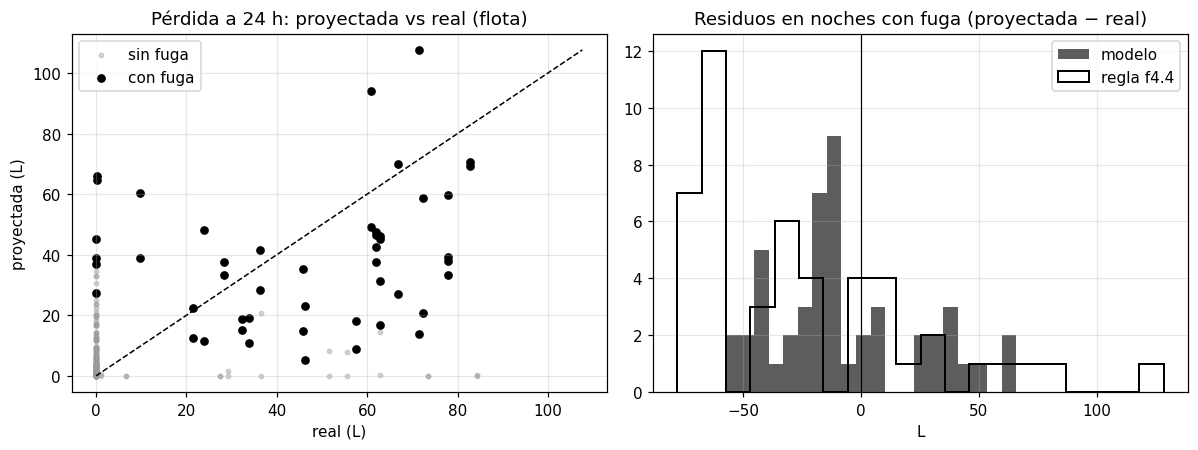

In [9]:
c = flota_p[(flota_p["particion"] == "consistencia") & (flota_p["uso"] == "evaluacion") & flota_p["evaluable"]]
fuga = c["etiqueta"] == "fuga_lenta"
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].scatter(c.loc[~fuga, "perdida_24h_real_l"], c.loc[~fuga, "perdida_24h_l"], s=8, c="0.6", alpha=0.4, label="sin fuga")
axs[0].scatter(c.loc[fuga, "perdida_24h_real_l"], c.loc[fuga, "perdida_24h_l"], s=22, c="k", label="con fuga")
lim = [0, max(c["perdida_24h_real_l"].max(), c["perdida_24h_l"].max())]
axs[0].plot(lim, lim, "k--", lw=1)
axs[0].set(title="Pérdida a 24 h: proyectada vs real (flota)", xlabel="real (L)", ylabel="proyectada (L)"); axs[0].legend()
axs[1].hist((c["perdida_24h_l"] - c["perdida_24h_real_l"])[fuga], bins=20, color="0.25", alpha=0.85, label="modelo")
axs[1].hist((c["base_c_24h"] - c["perdida_24h_real_l"])[fuga], bins=20, histtype="step", color="k", lw=1.3, label="regla f4.4")
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set(title="Residuos en noches con fuga (proyectada − real)", xlabel="L"); axs[1].legend()
plt.tight_layout(); plt.show()

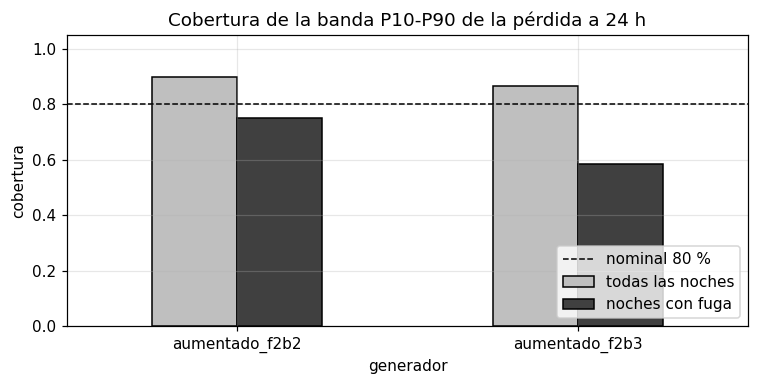

,todas las noches,noches con fuga
generador,,
aumentado_f2b2,0.896,0.750
aumentado_f2b3,0.866,0.583


In [10]:
filas = []
for f in res_flota:
    b = res_flota[f]["perdida"]["24h"]["banda_p10_p90"]
    filas.append({"generador": f, "todas las noches": b["cobertura"]["valor"], "noches con fuga": b["cobertura_noches_con_fuga"]["valor"]})
cob = pd.DataFrame(filas).set_index("generador")
ax = cob.plot.bar(color=["0.75", "0.25"], edgecolor="k", figsize=(7, 3.6), rot=0)
ax.axhline(0.8, color="k", ls="--", lw=1, label="nominal 80 %"); ax.set_ylim(0, 1.05)
ax.set(title="Cobertura de la banda P10-P90 de la pérdida a 24 h", ylabel="cobertura"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
display(cob)

## 6. En vivo (F7): últimas predicciones y pronóstico frente a real

La consulta `predicciones` del job de Spark (F7) aplica este mismo modelo versionado a cada micro-lote y escribe en
InfluxDB (measurement `predicciones`, `dimension = D6`). Se leen las últimas estimaciones y las verificaciones
(`tipo = verificacion`: el pronóstico comparado con lo que pasó de verdad en el instante objetivo). Los datos reales
están en el bucket `monitoraqua`; la flota extrapolada, en `monitoraqua_aumentados` (fechas simuladas 28-sep a 28-oct).

In [11]:
est = su.predicciones("D6", "estimacion", horas=48, limite=400)
if len(est):
    ult = est.sort_values("_time").groupby("sensorId").tail(1)
    cols = [c for c in ["_time", "sensorId", "version_modelo", *['tasa_lph', 'exceso_lph', 'p_fuga', 'fuga', 'perdida_24h_l', 'perdida_24h_p10_l', 'perdida_24h_p90_l'], "advertencia"] if c in ult]
    display(ult[cols].reset_index(drop=True))
else:
    print("Sin estimaciones reales en las últimas 48 h")
mot = su.predicciones("D6", "motivo", horas=48, limite=400)
if len(mot):
    mot = mot.sort_values("_time").groupby("sensorId").tail(1)
    if len(est):   # vigente: solo si el tanque no tuvo una estimación posterior al motivo
        ult_est = est.groupby("sensorId")["_time"].max()
        mot = mot[mot["_time"] > mot["sensorId"].map(ult_est).fillna(pd.Timestamp(0, tz="America/Lima"))]
    print("Tanques reales donde hoy el modelo no aplica (motivo vigente):")
    display(mot[["_time", "sensorId", "motivo"]].reset_index(drop=True))

Sin estimaciones reales en las últimas 48 h
Tanques reales donde hoy el modelo no aplica (motivo vigente):


,_time,sensorId,motivo
0,2026-10-29 03:30:00-05:00,esp32-tanque-real-01,geometría provisional (por_medir): los litros ...


In [12]:
ver_real = su.predicciones("D6", "verificacion", horas=48)
ver_flota = su.predicciones("D6", "verificacion", bucket="monitoraqua_aumentados", horas=1440)
for nombre, v in (("real", ver_real), ("flota", ver_flota)):
    if len(v) and "perdida_real_proxy_l" in v and "perdida_pred_l" in v:
        v = v.dropna(subset=["perdida_real_proxy_l", "perdida_pred_l"])
        err = (v["perdida_real_proxy_l"] - v["perdida_pred_l"]) * 1.0
        r2 = "" if 1.0 != 1.0 else f" · R² {su.r2(v['perdida_real_proxy_l'], v['perdida_pred_l']):.3f}"
        print(f"{nombre}: {len(v)} pronósticos verificados · MAE en vivo {err.abs().mean():.3f} · "
              f"sesgo {(-err).mean():+.3f}{r2}")
        display(v.assign(_e=err.abs()).groupby("sensorId")["_e"].agg(verificados="count", MAE="mean").round(3))
    else:
        print(f"{nombre}: todavía sin verificaciones de D6 (ver docs/inferencia-en-vivo.md, pendientes)")

real: todavía sin verificaciones de D6 (ver docs/inferencia-en-vivo.md, pendientes)
flota: 104 pronósticos verificados · MAE en vivo 12.421 · sesgo -8.775 · R² -0.551


,verificados,MAE
sensorId,,
flota-zonaA-01,26,12.960
flota-zonaA-02,26,8.356
flota-zonaB-01,26,10.368
flota-zonaB-02,26,18.002


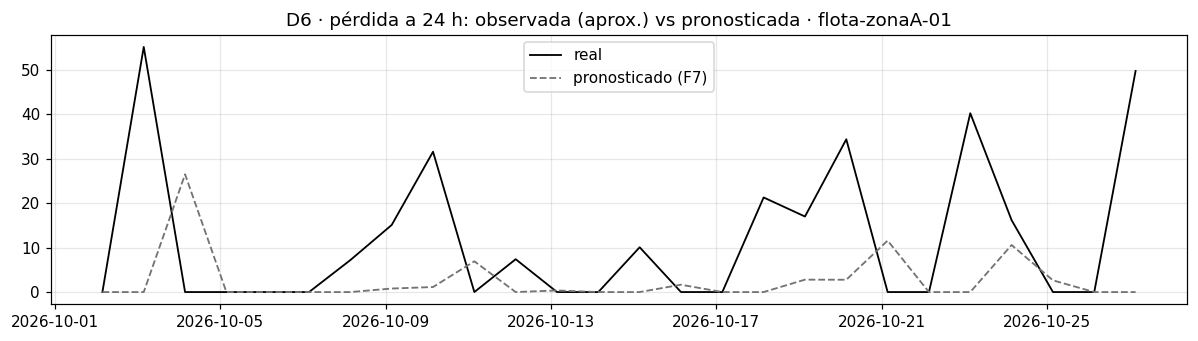

In [13]:
v = ver_flota if len(ver_flota) else ver_real
if len(v) and "perdida_real_proxy_l" in v:
    v = v.dropna(subset=["perdida_real_proxy_l", "perdida_pred_l"])
    s = v["sensorId"].value_counts().index[0]
    g = v[v["sensorId"] == s].sort_values("_time")
    fig, ax = plt.subplots(figsize=(11, 3.2))
    if 1.0 != 1.0:   # D4: error de la hora de llegada en horas
        ax.bar(g["_time"], (g["perdida_real_proxy_l"] - g["perdida_pred_l"]) * 1.0, width=0.05, color="0.3")
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("real − pronosticada (h)")
    else:
        ax.plot(g["_time"], g["perdida_real_proxy_l"], "k-", lw=1.2, label="real")
        ax.plot(g["_time"], g["perdida_pred_l"], "--", color="0.45", lw=1.2, label="pronosticado (F7)"); ax.legend()
    ax.set_title(f"D6 · pérdida a 24 h: observada (aprox.) vs pronosticada · {s}"); plt.tight_layout(); plt.show()

## 7. Limitaciones (copiadas de `docs/modelo-d6.md`)

In [14]:
display(Markdown(su.secciones("modelo-d6.md", ['Limitaciones'])))

## 9. Limitaciones

- **Limitación principal: la franja nocturna es fija (00:00-03:30) y no sirve cuando el agua llega de madrugada.**
  - **Lo que pasó en ThingSpeak:** en 1233810, el tanque doméstico real, el agua llega de noche en **52 de sus 59
    noches**, así que casi ninguna noche queda sin llenado dentro de la franja.
  - **Por qué importa en Juliaca:** el suministro intermitente también suele llegar de noche o de madrugada (la franja
    de llegada de la flota es de 4-8 h, y la de 1233810, de 01-02 h). La misma franja fija dejaría sin noches
    evaluables a muchos tanques reales.
  - **Mejora d6.2:** calcular la franja de mínimo consumo **por tanque**, con las horas de llegada de D4 (la
    distribución de la hora de llegada de cada tanque). Se elige la ventana de 3-4 h sin llegadas probables y con el
    menor consumo, en lugar de 00:00-03:30 para todos.
- **No hay ninguna fuga real etiquetada.** Todo lo cuantitativo sale de la flota: fugas constantes de 1.5-4 L/h que
  duran 1-4 días. Una fuga real puede crecer, intermitir o empezar de día; ninguna de esas formas se evaluó. La primera
  evidencia real será la fuga controlada.
- **La referencia necesita 3 noches válidas anteriores.** Un tanque nuevo, o uno que vuelve de un hueco largo, no se
  puntúa las primeras noches. Una fuga que ya existía al empezar queda dentro de la referencia y no se ve.
- **La banda a 24 h cubre el 58-75 % de las noches con fuga, no el 80 %.**
- **La proyección a 7 días tiene solo 5 casos con fuga:** no se usa en F7.
- **La geometría del ESP32 es provisional:** los L/h del ESP32 cambian cuando se mida el recipiente.
